In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS_DIR = Path('results')
GRAPHS_DIR = Path('graphs')
GRAPHS_DIR.mkdir(exist_ok=True)

In [2]:
df = pd.read_csv(RESULTS_DIR / 'ejercicio1_suma_matriz.csv').sort_values('threads')
df

,threads,t_filas_s,t_columnas_s,speedup_filas,speedup_columnas,eficiencia_filas_pct,eficiencia_columnas_pct,ratio_col_vs_fila
0,1,0.116958,1.147667,1.0000,1.0000,100.00,100.00,9.8126
1,2,0.062752,0.638785,1.8638,1.7966,93.19,89.83,10.1795
2,4,0.037960,0.369754,3.0811,3.1039,77.03,77.60,9.7406
3,8,0.040625,0.250398,2.8790,4.5834,35.99,57.29,6.1637
4,16,0.041934,0.200547,2.7891,5.7227,17.43,35.77,4.7824


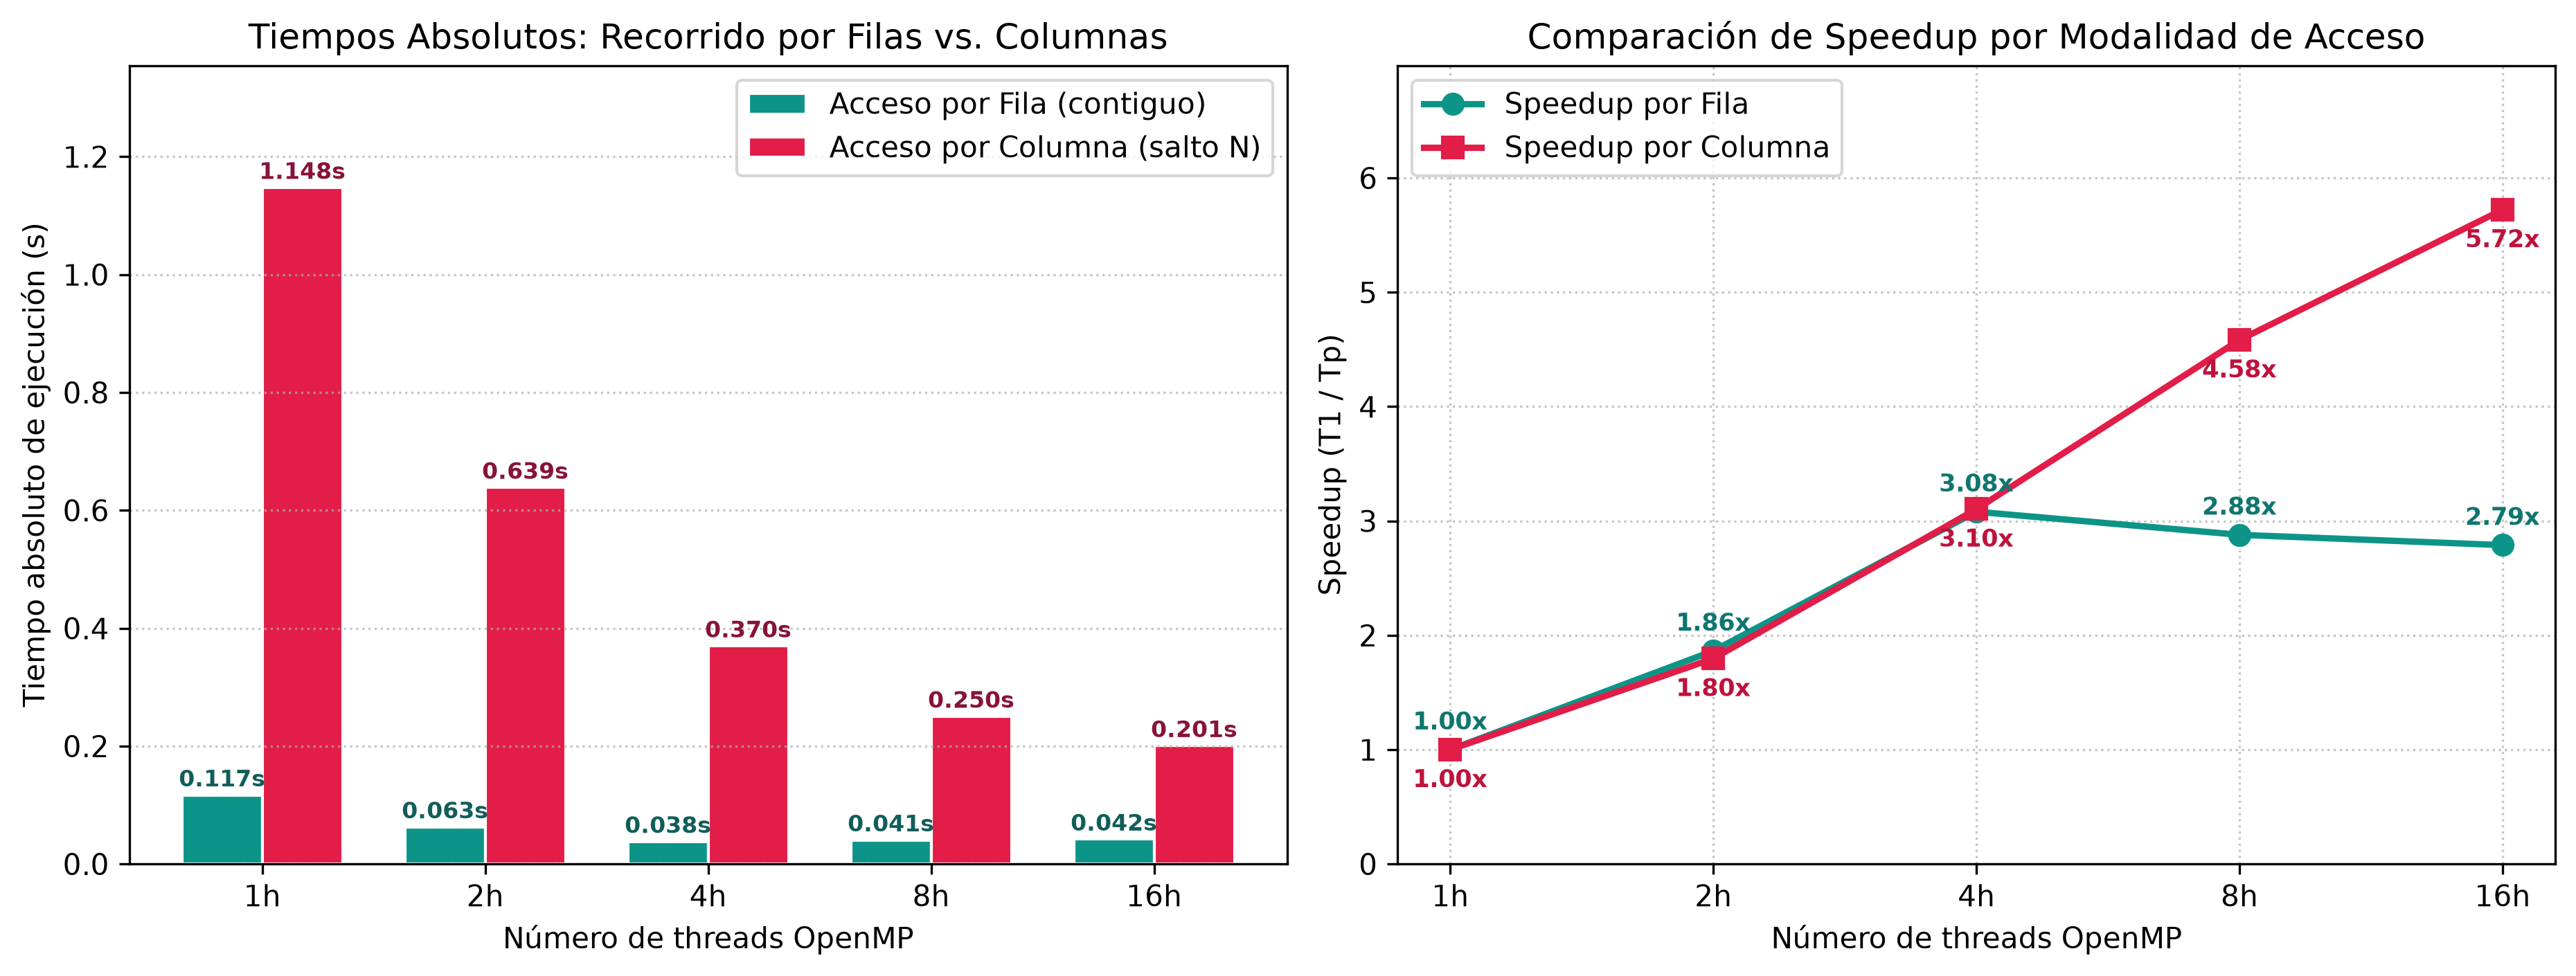

In [3]:
etiquetas = [f'{t}h' for t in df['threads']]
x = np.arange(len(etiquetas))
ancho = 0.36

t_filas = df['t_filas_s'].to_numpy()
t_cols = df['t_columnas_s'].to_numpy()
sp_filas = df['speedup_filas'].to_numpy()
sp_cols = df['speedup_columnas'].to_numpy()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8), dpi=300)

# Panel izquierdo: Tiempos absolutos por fila vs por columna
b1 = ax1.bar(x - ancho / 2, t_filas, ancho, color='#0d9488', edgecolor='white', label='Acceso por Fila (contiguo)')
b2 = ax1.bar(x + ancho / 2, t_cols, ancho, color='#e11d48', edgecolor='white', label='Acceso por Columna (salto N)')

for b in b1:
    h = b.get_height()
    ax1.annotate(f'{h:.3f}s', (b.get_x() + b.get_width() / 2, h),
                 xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8, color='#115e59', fontweight='bold')
for b in b2:
    h = b.get_height()
    ax1.annotate(f'{h:.3f}s', (b.get_x() + b.get_width() / 2, h),
                 xytext=(0, 3), textcoords='offset points', ha='center', fontsize=8, color='#881337', fontweight='bold')

ax1.set_xticks(x)
ax1.set_xticklabels(etiquetas)
ax1.set_ylim(0, max(t_cols) * 1.18)
ax1.set_xlabel('Número de threads OpenMP')
ax1.set_ylabel('Tiempo absoluto de ejecución (s)')
ax1.set_title('Tiempos Absolutos: Recorrido por Filas vs. Columnas')
ax1.legend()
ax1.grid(True, axis='y', linestyle=':', alpha=0.7)

# Panel derecho: Speedup relativo a 1 hilo de cada modalidad
ax2.plot(x, sp_filas, marker='o', markersize=7, linewidth=2.2, color='#0d9488', label='Speedup por Fila')
ax2.plot(x, sp_cols, marker='s', markersize=7, linewidth=2.2, color='#e11d48', label='Speedup por Columna')

for xi, yf, yc in zip(x, sp_filas, sp_cols):
    ax2.annotate(f'{yf:.2f}x', (xi, yf), xytext=(0, 7), textcoords='offset points',
                 ha='center', fontsize=8.5, color='#0f766e', fontweight='bold')
    ax2.annotate(f'{yc:.2f}x', (xi, yc), xytext=(0, -13), textcoords='offset points',
                 ha='center', fontsize=8.5, color='#be123c', fontweight='bold')

ax2.set_xticks(x)
ax2.set_xticklabels(etiquetas)
ax2.set_ylim(0, max(max(sp_filas), max(sp_cols)) * 1.22)
ax2.set_xlabel('Número de threads OpenMP')
ax2.set_ylabel('Speedup (T1 / Tp)')
ax2.set_title('Comparación de Speedup por Modalidad de Acceso')
ax2.legend(loc='upper left')
ax2.grid(True, linestyle=':', alpha=0.7)

plt.tight_layout()
plt.savefig(GRAPHS_DIR / 'e1_suma_matriz_omp.png', dpi=300)
plt.show()